# Cuboid Delaunay 256-Case Lookup Table Visualization

Verification and visualization of the symmetry-broken 3D Delaunay triangulation lookup table (`LUT`) across all $2^8 = 256$ binary corner configurations of a $2 \times 2 \times 2$ voxel cell.

In [1]:
# %% 1. Imports and parameters
import math

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np
from numpy.typing import NDArray

from neuromodes.mesh import build_cubic_delaunay_lut, _CUBE_CORNERS

# Unit cube corner coordinates ordered by (x, y, z) in {0, 1}^3
BIT_WEIGHTS: NDArray[np.int32] = 1 << np.arange(7, -1, -1, dtype=np.int32)
CUBE_CENTER: NDArray[np.float64] = np.array([0.5, 0.5, 0.5], dtype=np.float64)

# All 12 edges of the unit cube
CUBE_EDGES: list[tuple[int, int]] = [
    (i, j)
    for i in range(8)
    for j in range(i + 1, 8)
    if int(np.sum(np.abs(_CUBE_CORNERS[i] - _CUBE_CORNERS[j]))) == 1
]

# The 6 axis-aligned cube faces: (label, axis, value)
FACES_SPEC: list[tuple[str, int, int]] = [
    ("x = 0", 0, 0),
    ("x = 1", 0, 1),
    ("y = 0", 1, 0),
    ("y = 1", 1, 1),
    ("z = 0", 2, 0),
    ("z = 1", 2, 1),
]
FACE_VERTS_MAP: dict[str, NDArray[np.intp]] = {
    label: np.flatnonzero(_CUBE_CORNERS[:, axis] == val)
    for label, axis, val in FACES_SPEC
}

# Visualization parameters
EXPLODE: float = 0.15
ELEV: float = 22.0
AZIM: float = -38.0
TET_COLORS: list[str] = ["#0072BD", "#D95319", "#EDB120", "#7E2F8E", "#77AC30", "#4DBEEE"]


In [2]:
# %% 2. Plotting helper functions
def case_to_active_mask(case_id: int) -> NDArray[np.bool_]:
    """Convert an integer case ID in [0, 255] to an 8-element boolean corner mask."""
    return np.array([(case_id >> (7 - b)) & 1 for b in range(8)], dtype=bool)

def get_face_edges(face_verts: NDArray[np.intp]) -> set[tuple[int, int]]:
    """Return the 4 cube edges bounding a given 4-vertex face."""
    return {
        (int(u), int(v))
        for idx_u, u in enumerate(face_verts)
        for v in face_verts[idx_u + 1 :]
        if int(np.sum(np.abs(_CUBE_CORNERS[u] - _CUBE_CORNERS[v]))) == 1
    }

def get_filled_faces(active_mask: NDArray[np.bool_]) -> list[str]:
    """Return labels of all cube faces whose 4 corners are all active."""
    return [
        label for label, f_verts in FACE_VERTS_MAP.items() if np.all(active_mask[f_verts])
    ]

def plot_lut_case(
    ax,
    case_id: int,
    tets: NDArray[np.int32],
    *,
    highlight_verts: NDArray[np.intp] | None = None,
    highlight_edges: set[tuple[int, int]] | None = None,
    explode: float = EXPLODE,
    elev: float = ELEV,
    azim: float = AZIM,
    title: str | None = None,
    title_fontsize: float = 8.5,
    title_fontweight: str = "normal",
    title_pad: float = 0.0,
    show_empty_shapes: bool = True,
) -> None:
    """Render a single 2x2x2 LUT configuration on a 3D Matplotlib axis."""
    active_mask = case_to_active_mask(case_id)
    act_pts = _CUBE_CORNERS[active_mask].astype(np.float64)
    inact_pts = _CUBE_CORNERS[~active_mask]
    n_verts = int(active_mask.sum())

    # Draw cube wireframe (highlighting target face edges when provided)
    hl_edges = highlight_edges or set()
    for i, j in CUBE_EDGES:
        seg = _CUBE_CORNERS[[i, j]]
        if (i, j) in hl_edges or (j, i) in hl_edges:
            ax.plot(seg[:, 0], seg[:, 1], seg[:, 2], color="crimson", ls="-", lw=1.2, alpha=0.65, zorder=2)
        else:
            ax.plot(seg[:, 0], seg[:, 1], seg[:, 2], color="lightgrey", ls=":", lw=0.8, zorder=1)

    # Draw exploded tetrahedra batched into a single Poly3DCollection for clean 3D depth sorting
    if tets.size > 0:
        all_faces: list[NDArray[np.float64]] = []
        all_colors: list[str] = []
        for t_idx, tet in enumerate(tets):
            pts = _CUBE_CORNERS[tet].astype(np.float64)
            pts = pts + explode * (pts.mean(axis=0) - CUBE_CENTER)
            all_faces.extend(
                [
                    pts[[0, 1, 2]],
                    pts[[0, 1, 3]],
                    pts[[0, 2, 3]],
                    pts[[1, 2, 3]],
                ]
            )
            all_colors.extend([TET_COLORS[t_idx % len(TET_COLORS)]] * 4)

        poly = Poly3DCollection(
            all_faces,
            facecolors=all_colors,
            edgecolors="black",
            linewidths=0.8,
            alpha=0.85,
        )
        ax.add_collection3d(poly)
    elif show_empty_shapes:
        if n_verts == 2:
            ax.plot(
                act_pts[:, 0], act_pts[:, 1], act_pts[:, 2],
                color="#1f77b4", lw=2.0, zorder=4,
            )
        elif n_verts == 3:
            tri = Poly3DCollection(
                [act_pts],
                facecolors="#1f77b4",
                edgecolors="#1f77b4",
                linewidths=1.2,
                alpha=0.22,
            )
            ax.add_collection3d(tri)
        elif n_verts == 4:
            # Order 4 coplanar vertices cyclically around their centroid
            center = act_pts.mean(axis=0)
            u_axis = act_pts[0] - center
            normal = np.cross(u_axis, act_pts[1] - center)
            if np.allclose(normal, 0):
                normal = np.cross(u_axis, act_pts[2] - center)
            v_axis = np.cross(normal, u_axis)
            angles = np.arctan2((act_pts - center) @ v_axis, (act_pts - center) @ u_axis)
            ordered_pts = act_pts[np.argsort(angles)]

            is_cube_face = bool(np.any(np.all(act_pts == act_pts[0], axis=0)))
            quad_color = "crimson" if is_cube_face else "#ff7f0e"
            quad = Poly3DCollection(
                [ordered_pts],
                facecolors=quad_color,
                edgecolors=quad_color,
                linewidths=1.2,
                alpha=0.20,
            )
            ax.add_collection3d(quad)

    # Plot corner markers: highlighted active (crimson), other active (black), inactive (open grey)
    if highlight_verts is not None and len(highlight_verts) > 0:
        hl_pts = _CUBE_CORNERS[highlight_verts]
        ax.scatter(hl_pts[:, 0], hl_pts[:, 1], hl_pts[:, 2], color="crimson", s=28, zorder=6)
        other_active = active_mask.copy()
        other_active[highlight_verts] = False
        if np.any(other_active):
            o_pts = _CUBE_CORNERS[other_active]
            ax.scatter(o_pts[:, 0], o_pts[:, 1], o_pts[:, 2], color="black", s=24, zorder=5)
    elif len(act_pts) > 0:
        ax.scatter(act_pts[:, 0], act_pts[:, 1], act_pts[:, 2], color="black", s=24, zorder=5)

    if len(inact_pts) > 0:
        ax.scatter(
            inact_pts[:, 0],
            inact_pts[:, 1],
            inact_pts[:, 2],
            facecolors="white",
            edgecolors="silver",
            s=14,
            zorder=2,
        )

    ax.set_xlim(-0.15, 1.15)
    ax.set_ylim(-0.15, 1.15)
    ax.set_zlim(-0.15, 1.15)
    ax.set_box_aspect([1, 1, 1])
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()

    if title is None:
        title = f"#{case_id} ({n_verts}v, {len(tets)}t)"
    ax.set_title(title, fontsize=title_fontsize, fontweight=title_fontweight, pad=title_pad)


In [3]:
# %% 3. Build 256-case lookup table
lut = build_cubic_delaunay_lut()

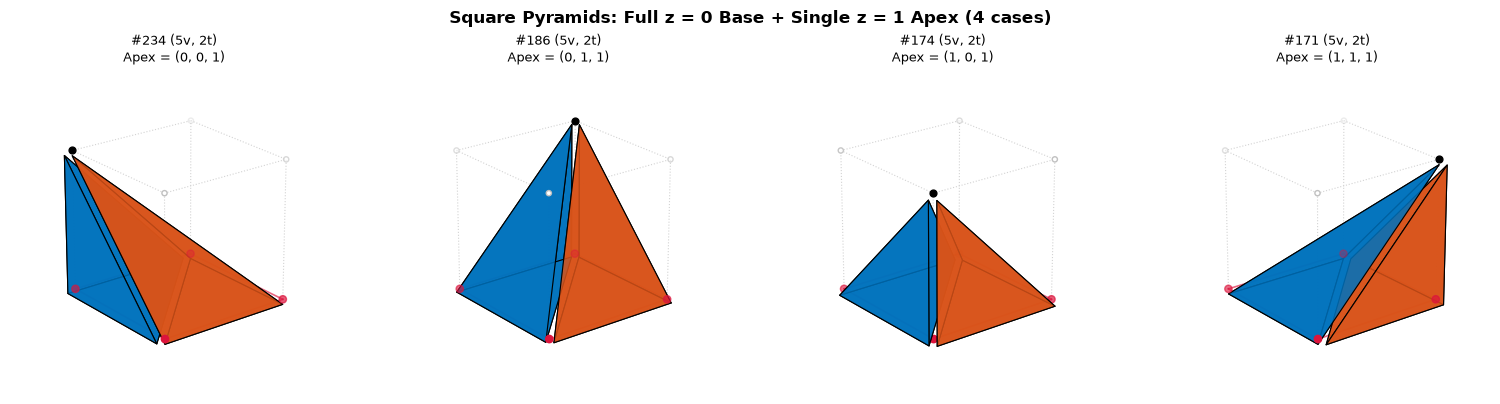

In [4]:
# %% 4. Plot 4 cases: all of z = 0 selected + 1 vertex from top face (z = 1)
z0_verts = FACE_VERTS_MAP["z = 0"]
z1_verts = FACE_VERTS_MAP["z = 1"]
z0_edges = get_face_edges(z0_verts)

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.0), subplot_kw={"projection": "3d"})
fig.suptitle(
    "Square Pyramids: Full z = 0 Base + Single z = 1 Apex (4 cases)",
    fontsize=12,
    fontweight="bold",
    y=0.98,
)

for ax, apex_idx in zip(axes, z1_verts):
    active_mask = np.zeros(8, dtype=bool)
    active_mask[z0_verts] = True
    active_mask[apex_idx] = True
    case_id = int(active_mask @ BIT_WEIGHTS)
    apex_coord = tuple(_CUBE_CORNERS[apex_idx].tolist())

    plot_lut_case(
        ax,
        case_id,
        lut[case_id],
        highlight_verts=z0_verts,
        highlight_edges=z0_edges,
        title=f"#{case_id} (5v, {len(lut[case_id])}t)\nApex = {apex_coord}",
        title_fontsize=9.5,
        title_pad=2.0,
    )

plt.subplots_adjust(left=0.01, right=0.99, top=0.84, bottom=0.02, wspace=0.05)
plt.show()


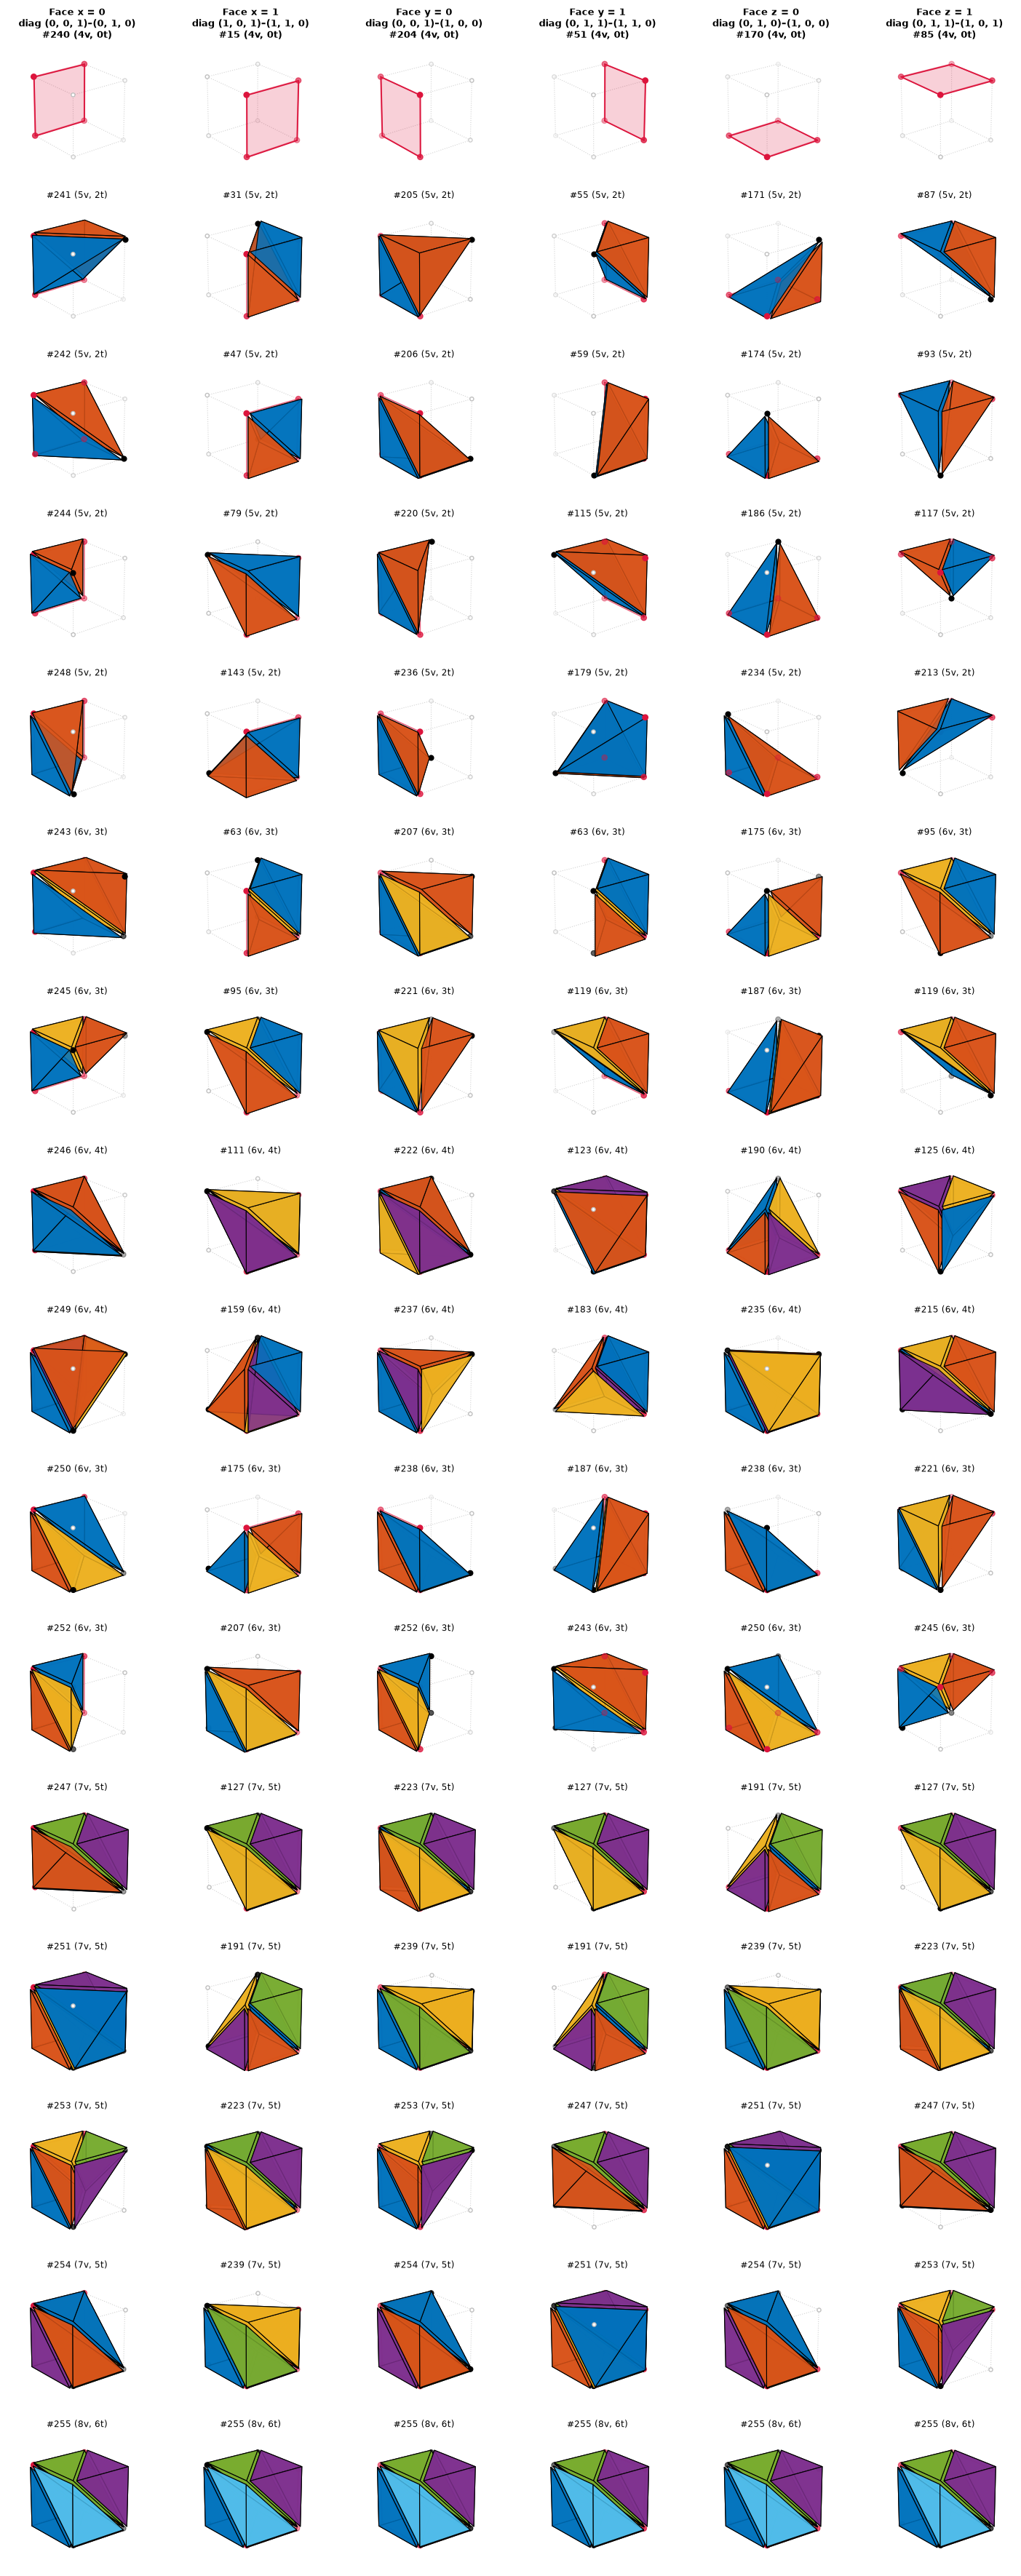

In [5]:
# %% 5. Plot all cases where at least 1 face is completely filled (16 rows x 6 cols)
full_edges = {
    tuple(sorted((int(tet[i]), int(tet[j]))))
    for tet in lut[255]
    for i in range(4)
    for j in range(i + 1, 4)
}

fig, axes = plt.subplots(
    16,
    6,
    figsize=(14.5, 36.0),
    subplot_kw={"projection": "3d"},
)

for col_idx, (face_label, axis, val) in enumerate(FACES_SPEC):
    face_verts = FACE_VERTS_MAP[face_label]
    face_edges = get_face_edges(face_verts)

    # Determine the shared diagonal chosen on this face
    diag_a = (int(face_verts[0]), int(face_verts[3]))
    diag_b = (int(face_verts[1]), int(face_verts[2]))
    chosen_diag = diag_a if diag_a in full_edges else diag_b
    diag_str = (
        f"{tuple(_CUBE_CORNERS[chosen_diag[0]].tolist())}–"
        f"{tuple(_CUBE_CORNERS[chosen_diag[1]].tolist())}"
    )

    # 16 cases per face, sorted ascending so the 4-vertex (0-tet) base face is at row 0
    matching_cases = [
        (cid, int(case_to_active_mask(cid).sum()))
        for cid in range(256)
        if np.all(case_to_active_mask(cid)[face_verts])
    ]
    matching_cases.sort(key=lambda item: (item[1], item[0]))

    for row_idx, (case_id, n_verts) in enumerate(matching_cases):
        ax = axes[row_idx, col_idx]
        tets = lut[case_id]
        case_title = f"#{case_id} ({n_verts}v, {len(tets)}t)"
        if row_idx == 0:
            title = f"Face {face_label}\ndiag {diag_str}\n{case_title}"
            fsize, fweight, tpad = 9.0, "bold", 2.0
        else:
            title = case_title
            fsize, fweight, tpad = 8.5, "normal", 0.0

        plot_lut_case(
            ax,
            case_id,
            tets,
            highlight_verts=face_verts,
            highlight_edges=face_edges,
            title=title,
            title_fontsize=fsize,
            title_fontweight=fweight,
            title_pad=tpad,
        )

plt.subplots_adjust(left=0.01, right=0.99, top=0.97, bottom=0.005, wspace=0.04, hspace=0.14)
plt.show()


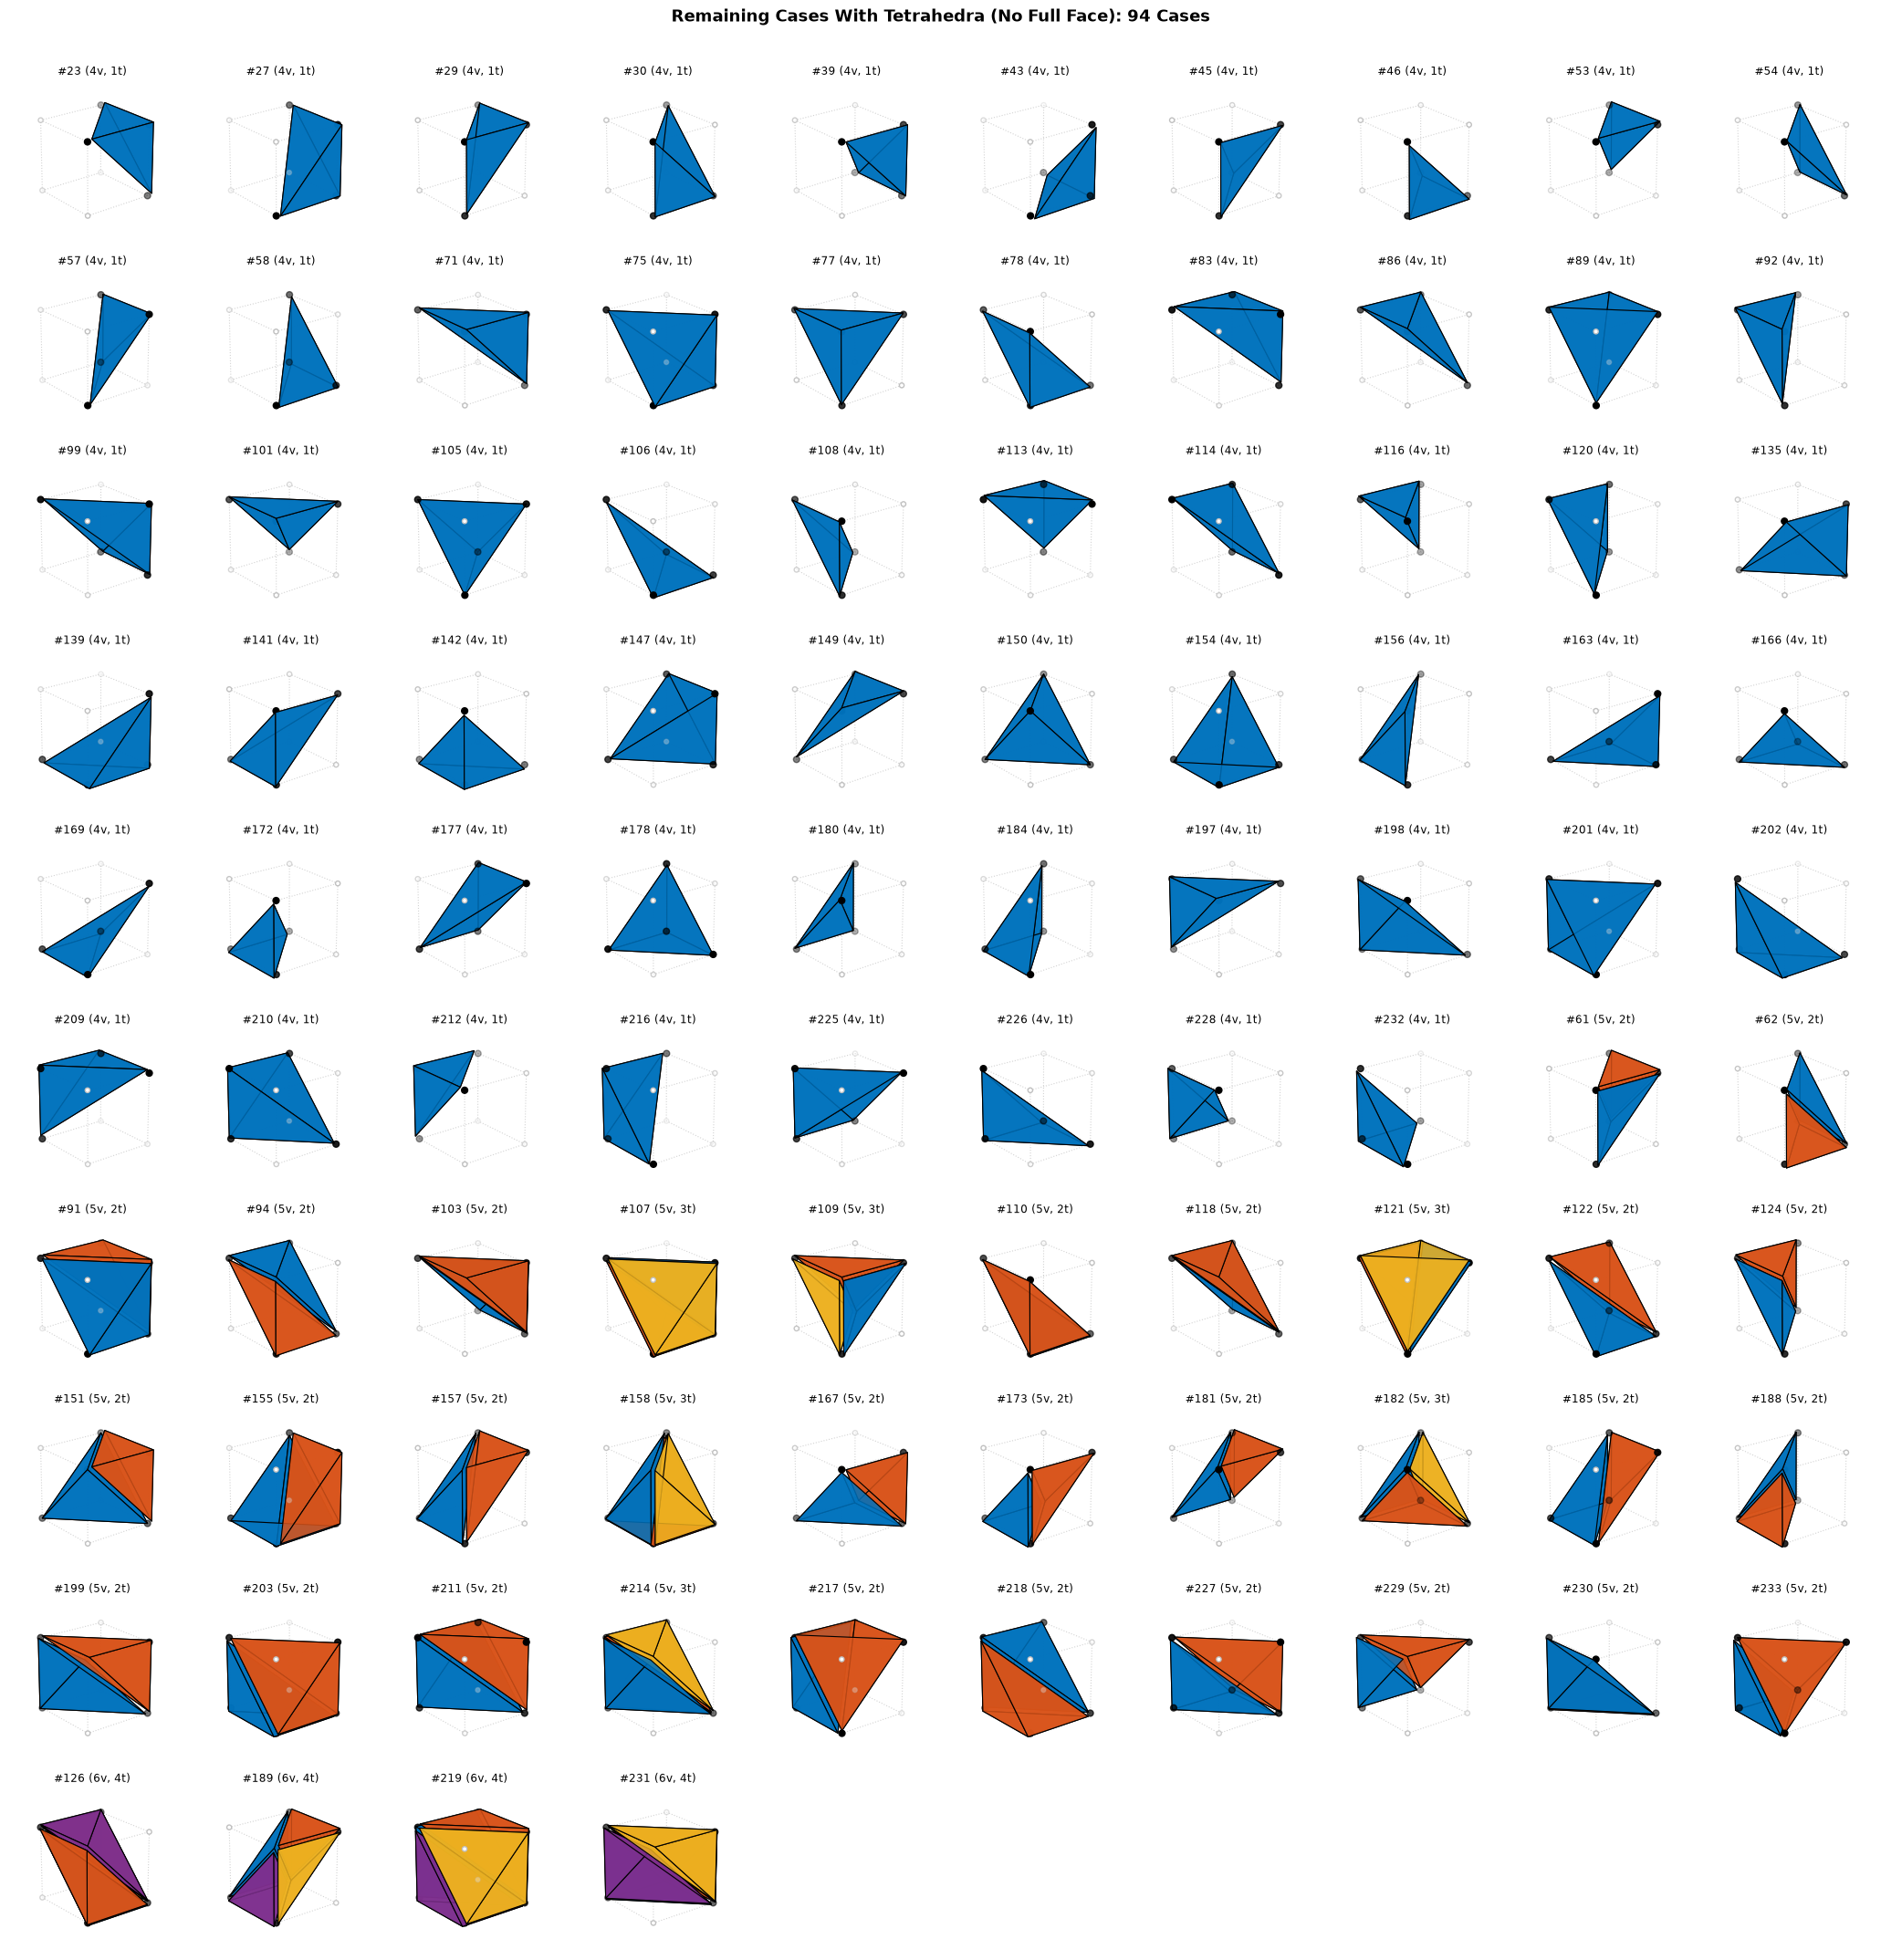

In [6]:
# %% 6. Plot all remaining cases WITH tetrahedra (no full face; 94 cases)
remaining_with_tets = [
    (cid, int(case_to_active_mask(cid).sum()))
    for cid, tets in enumerate(lut)
    if tets.size > 0 and not get_filled_faces(case_to_active_mask(cid))
]
remaining_with_tets.sort(key=lambda item: (item[1], item[0]))

ncols = 10
nrows = math.ceil(len(remaining_with_tets) / ncols)
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(21.0, 2.15 * nrows),
    subplot_kw={"projection": "3d"},
)
axes_flat = axes.ravel()

for ax, (case_id, n_verts) in zip(axes_flat, remaining_with_tets):
    plot_lut_case(ax, case_id, lut[case_id])

for ax in axes_flat[len(remaining_with_tets) :]:
    ax.set_visible(False)

fig.suptitle(
    f"Remaining Cases With Tetrahedra (No Full Face): {len(remaining_with_tets)} Cases",
    fontsize=13,
    fontweight="bold",
    y=0.995,
)
plt.subplots_adjust(left=0.01, right=0.99, top=0.96, bottom=0.005, wspace=0.04, hspace=0.14)
plt.show()


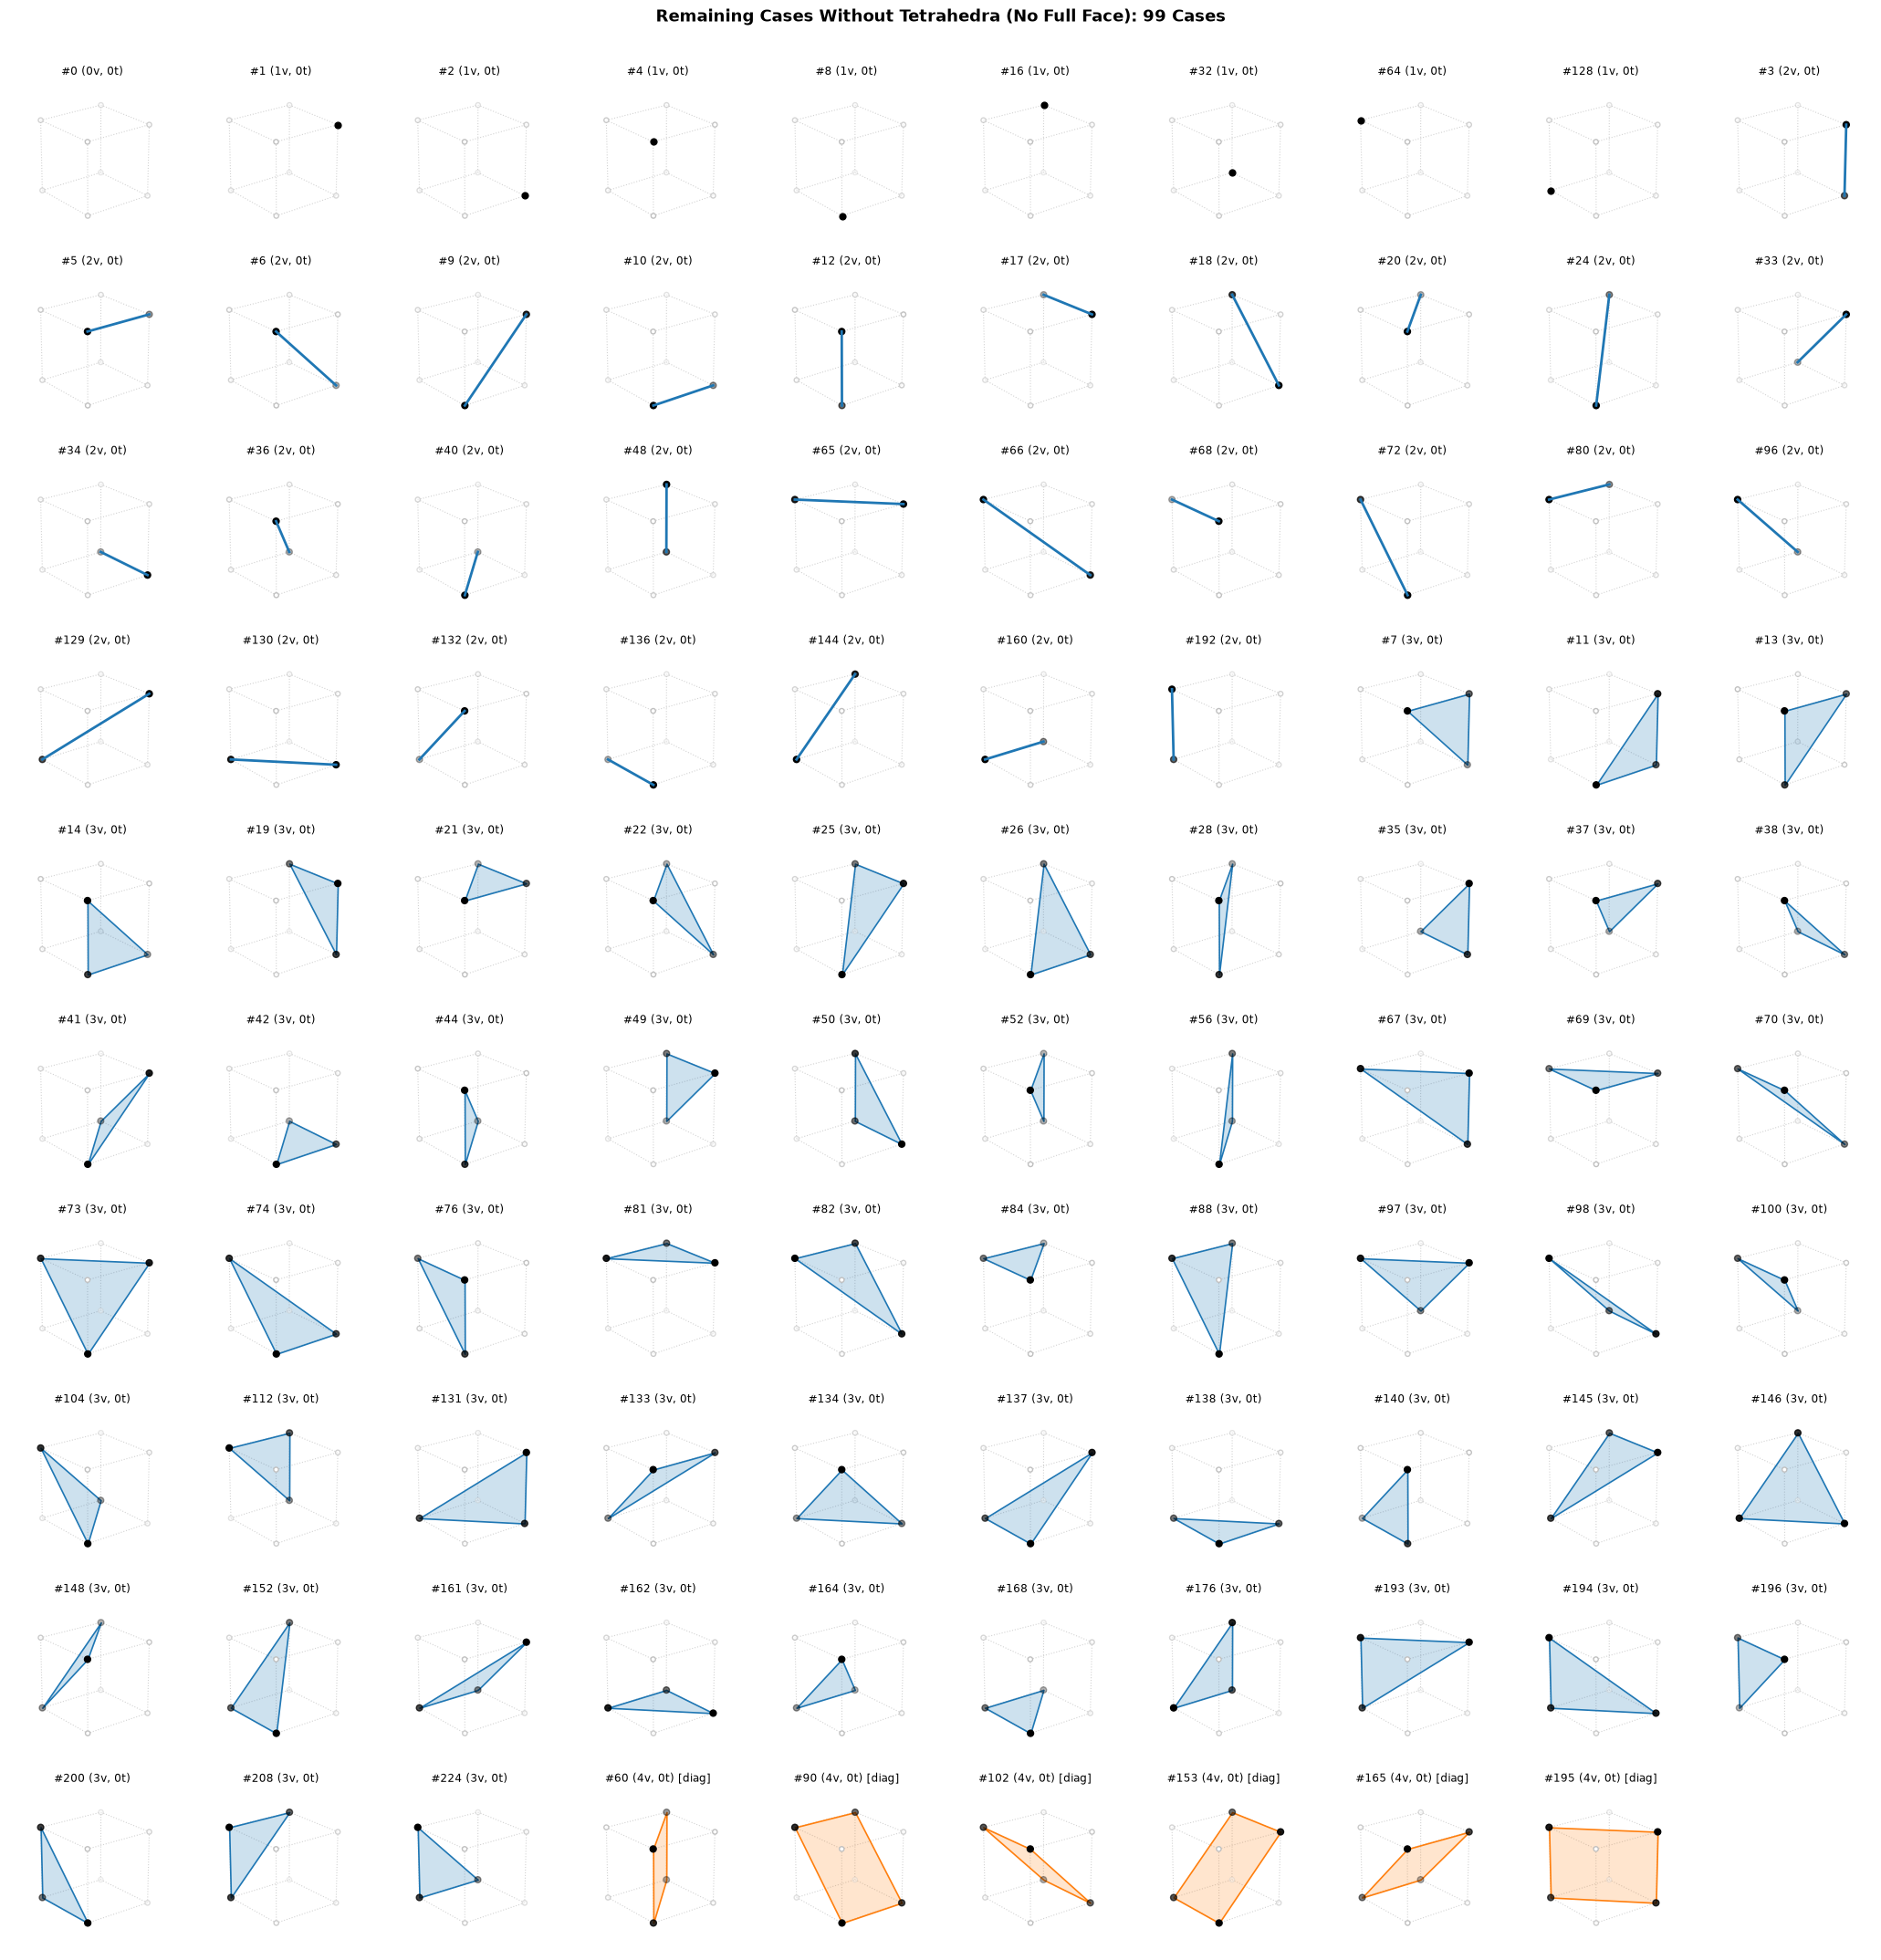

In [7]:
# %% 7. Plot all remaining cases WITHOUT tetrahedra (no full face; 99 cases)
remaining_without_tets = [
    (cid, int(case_to_active_mask(cid).sum()))
    for cid, tets in enumerate(lut)
    if tets.size == 0 and not get_filled_faces(case_to_active_mask(cid))
]
remaining_without_tets.sort(key=lambda item: (item[1], item[0]))

ncols = 10
nrows = math.ceil(len(remaining_without_tets) / ncols)
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(21.0, 2.15 * nrows),
    subplot_kw={"projection": "3d"},
)
axes_flat = axes.ravel()

for ax, (case_id, n_verts) in zip(axes_flat, remaining_without_tets):
    suffix = " [diag]" if n_verts == 4 else ""
    plot_lut_case(
        ax,
        case_id,
        lut[case_id],
        title=f"#{case_id} ({n_verts}v, 0t){suffix}",
    )

for ax in axes_flat[len(remaining_without_tets) :]:
    ax.set_visible(False)

fig.suptitle(
    f"Remaining Cases Without Tetrahedra (No Full Face): {len(remaining_without_tets)} Cases",
    fontsize=13,
    fontweight="bold",
    y=0.995,
)
plt.subplots_adjust(left=0.01, right=0.99, top=0.96, bottom=0.005, wspace=0.04, hspace=0.14)
plt.show()


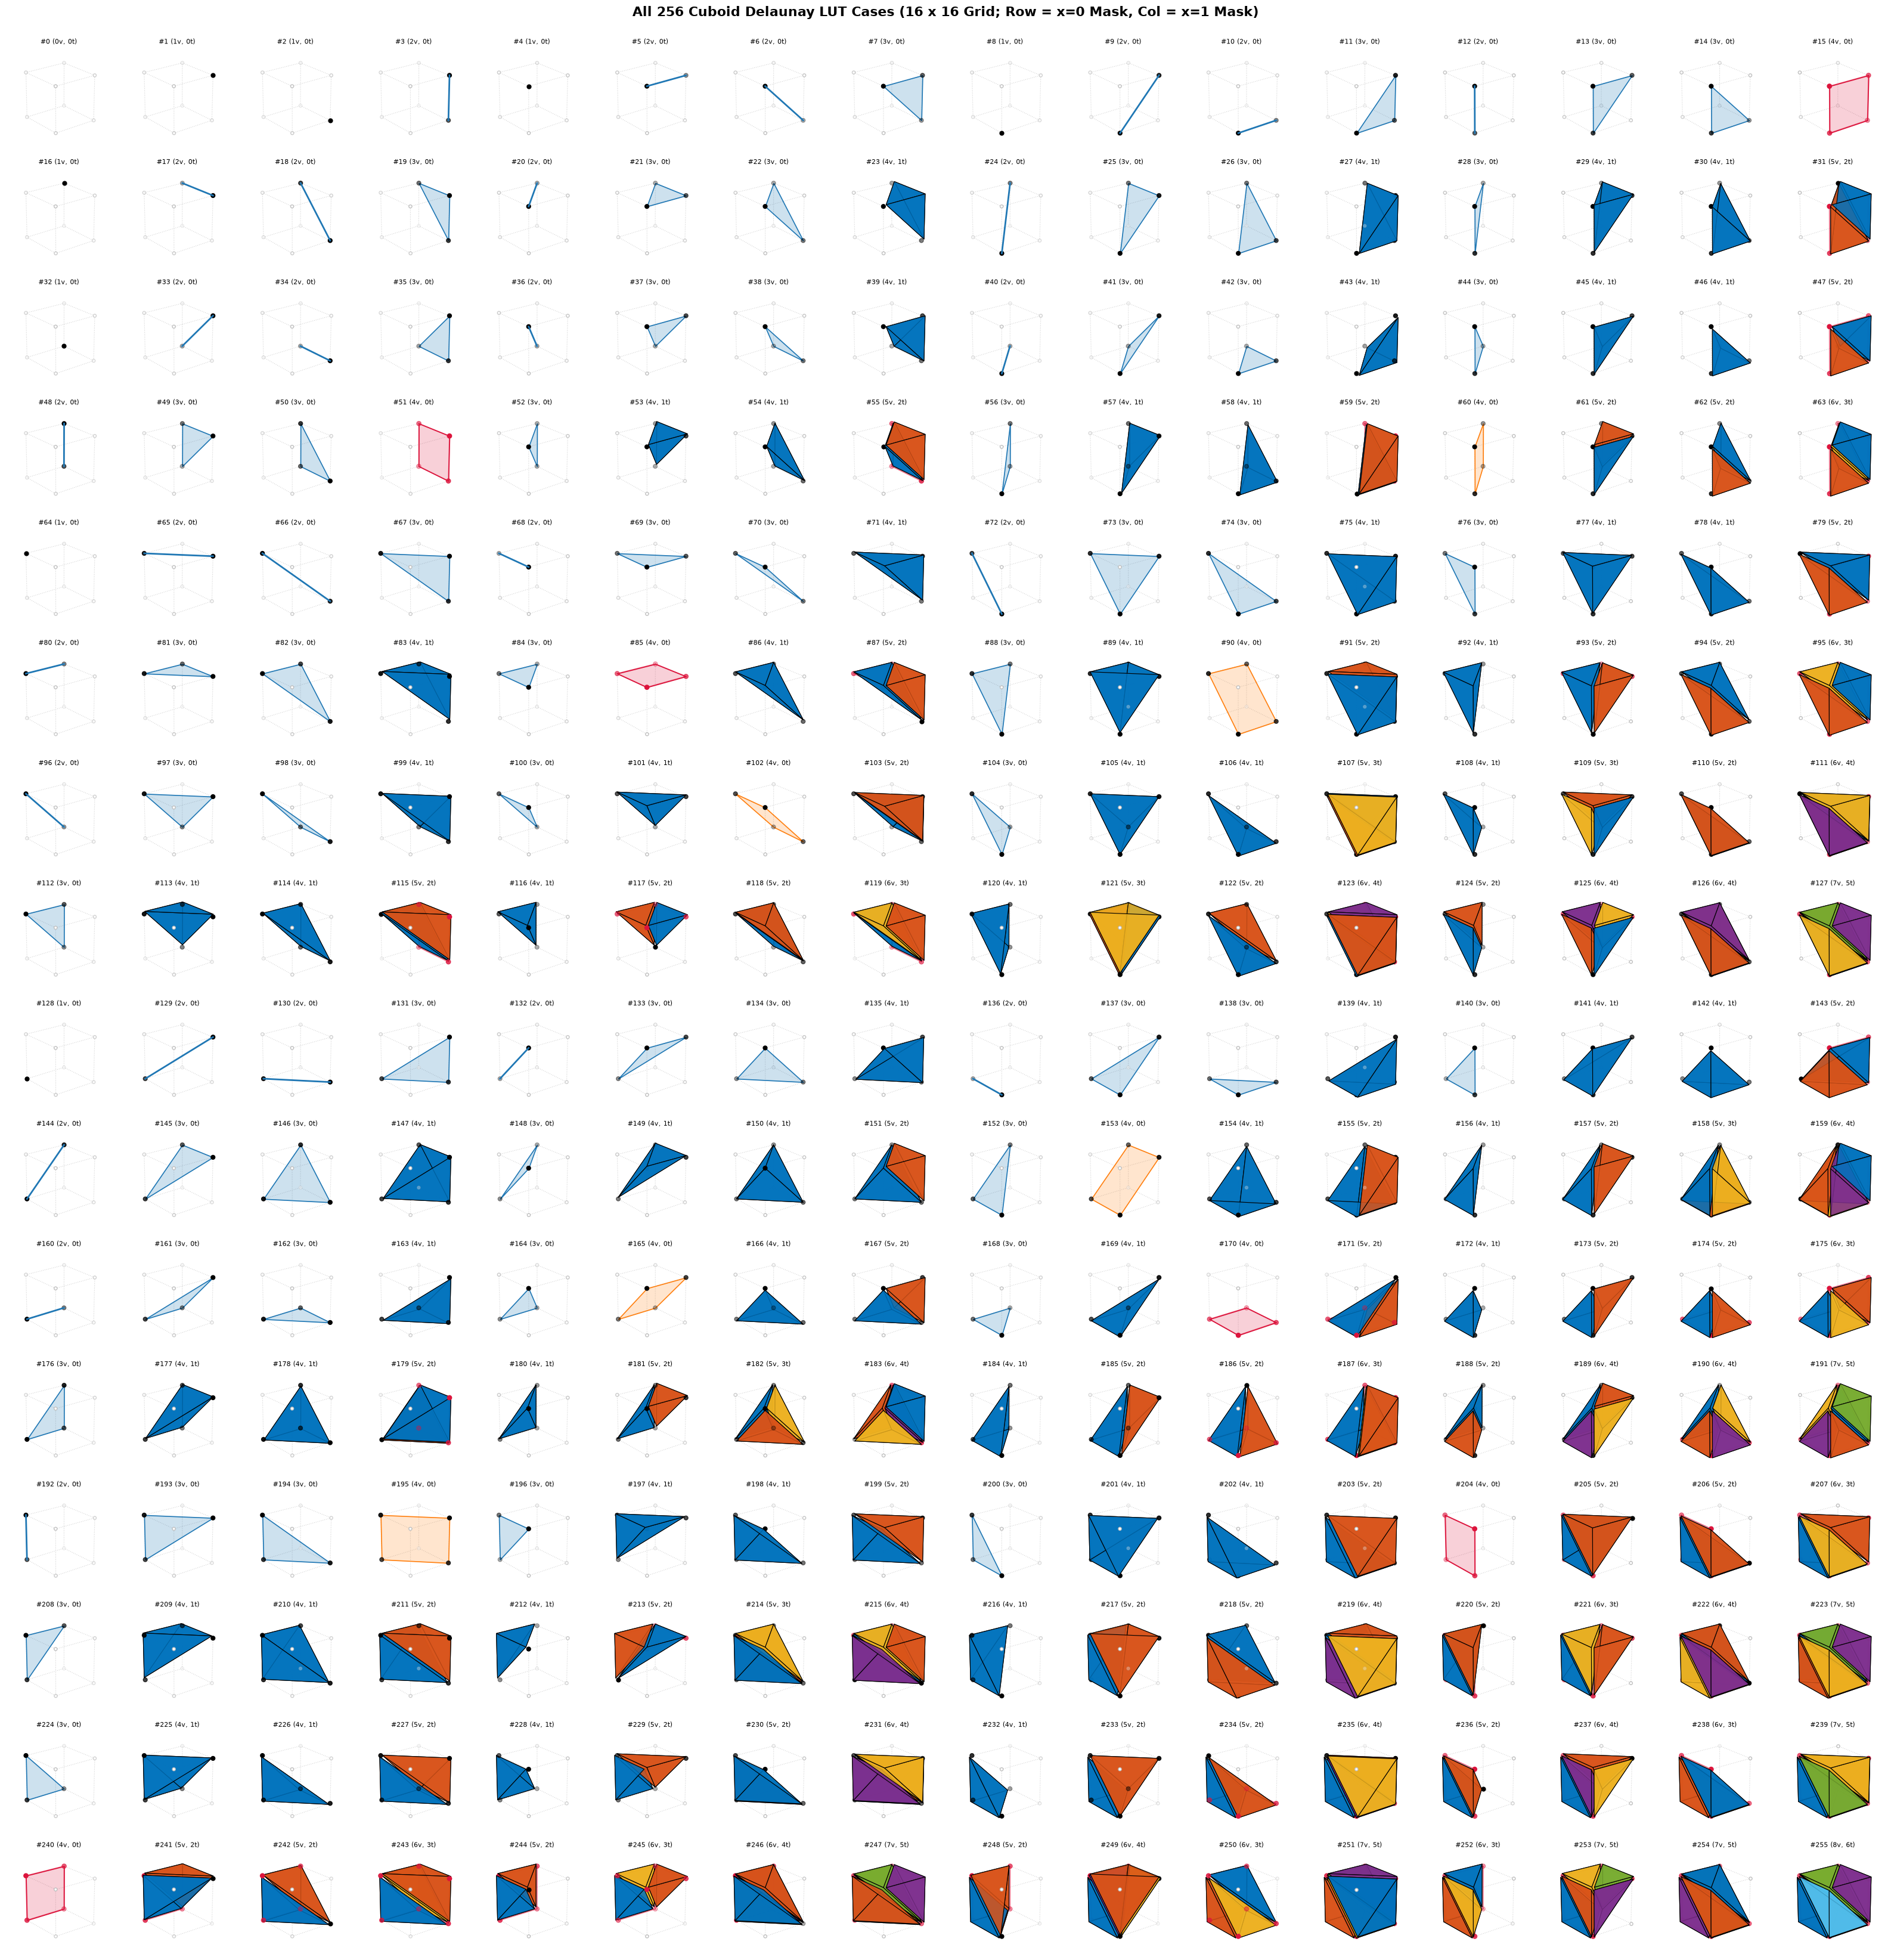

In [8]:
# %% 8. Plot all 256 cases on a 16 x 16 grid
fig, axes = plt.subplots(
    16,
    16,
    figsize=(32.0, 33.0),
    subplot_kw={"projection": "3d"},
)

for case_id, ax in enumerate(axes.ravel()):
    active_mask = case_to_active_mask(case_id)
    filled_labels = get_filled_faces(active_mask)
    hl_verts = (
        np.unique(np.concatenate([FACE_VERTS_MAP[lbl] for lbl in filled_labels]))
        if filled_labels
        else None
    )
    hl_edges = (
        set().union(*(get_face_edges(FACE_VERTS_MAP[lbl]) for lbl in filled_labels))
        if filled_labels
        else None
    )
    plot_lut_case(
        ax,
        case_id,
        lut[case_id],
        highlight_verts=hl_verts,
        highlight_edges=hl_edges,
        title_fontsize=8.0,
    )

fig.suptitle(
    "All 256 Cuboid Delaunay LUT Cases (16 x 16 Grid; Row = x=0 Mask, Col = x=1 Mask)",
    fontsize=16,
    fontweight="bold",
    y=0.995,
)
plt.subplots_adjust(left=0.005, right=0.995, top=0.975, bottom=0.005, wspace=0.03, hspace=0.14)
plt.show()
